In [1]:
# Python ≥3.5 is required
import sys
assert sys.version_info >= (3, 5)

# Scikit-Learn ≥0.20 is required
import sklearn
assert sklearn.__version__ >= "0.20"

# TensorFlow ≥2.0 is required
import tensorflow as tf
from tensorflow import keras
assert tf.__version__ >= "2.0"

import keras.backend as K

from keras.utils.vis_utils import plot_model

# Common imports
import numpy as np
import os

# to make this notebook's output stable across runs
np.random.seed(42)
tf.random.set_seed(42)

# To plot pretty figures
%matplotlib inline
import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rc('axes', labelsize=14)
mpl.rc('xtick', labelsize=12)
mpl.rc('ytick', labelsize=12)

In [2]:
# Try to make GPU memory allocation dynamic, so it doesn't slow down/crash
physical_devices = tf.config.list_physical_devices('GPU')
try:
    tf.config.experimental.set_memory_growth(physical_devices[0], True)
    # config = tf.compat.v1.ConfigProto()
    # config.gpu_options.allow_growth = True
    # session = tf.compat.v1.Session(config=config)
except:
    print('oh no.')
  # Invalid device or cannot modify virtual devices once initialized.
    pass

In [3]:
# Check and test that TensorFlow can use GPU/CUDA cores

# tf.debugging.set_log_device_placement(True)

print("Num GPUs Available: ", len(tf.config.list_physical_devices('GPU')))

# Create some tensors
a = tf.constant([[1.0, 2.0, 3.0], [4.0, 5.0, 6.0]])
b = tf.constant([[1.0, 2.0], [3.0, 4.0], [5.0, 6.0]])
c = tf.matmul(a, b)

tf.debugging.set_log_device_placement(False)
print(c)

Num GPUs Available:  1
tf.Tensor(
[[22. 28.]
 [49. 64.]], shape=(2, 2), dtype=float32)


In [4]:
from tensorflow.python.client import device_lib
device_lib.list_local_devices()

[name: "/device:CPU:0"
 device_type: "CPU"
 memory_limit: 268435456
 locality {
 }
 incarnation: 5820166729522350366,
 name: "/device:GPU:0"
 device_type: "GPU"
 memory_limit: 5748293632
 locality {
   bus_id: 1
   links {
   }
 }
 incarnation: 15050063567863977312
 physical_device_desc: "device: 0, name: NVIDIA GeForce RTX 3060 Ti, pci bus id: 0000:01:00.0, compute capability: 8.6"]

In [5]:
physical_devices

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

In [6]:
#The goal of this project is to use a Generative Adversarial Network (GAN) to generate supplemental data for histopathological brain tumor samples, providing a solution to the relative scarcity of publicly available brain tumor data for machine learning and other
# scientific endeavors.
#
# For the time being, we focus on creating a proof of concept that works on smaller iomages while we figure out how to work around the large filesizes of the Digital Brain Tunmour Atlas' histopathological slide images.
# The GAN should be context-agnostic, so it should work on any images of brain tumors.
# As such, for the proof of concept model, we use images from Kaggle's Brain Tumor MRI Dataset, which combines several datasets into one place: https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset?resource=download
# This data must be preprocessed, since images from different sources are of difference sizes.

In [7]:
# TO-DO LIST
#
# MAIN PROJECT: Import .csv of the data, identify which 3/4 types of brain tumors are most common.
#                     Related --> find out how to import .csv as pandas dataframe for easier working.
#               Determine how/where to save data????? The images are huge, 3TiB in total. Even just the ones we care about will take up a huge amount of space.
#               Determine and implement the best quantitative evaluation metric for this project.
#
# PROOF OF CONCEPT: Import the jpg images, crop

In [ ]:
pip install opencv-python

In [ ]:
pip install imutils

In [ ]:
pip install visualkeras

In [ ]:
pip install pydot

In [12]:
# import numpy as np 
from tqdm import tqdm
import cv2
# import os
import imutils

# change this to wherever your raw images are located
DATASET_PATH = ""


def crop_img(img):
	"""
	Finds the extreme points on the image and crops the rectangular out of them
	"""
	gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
	gray = cv2.GaussianBlur(gray, (3, 3), 0)

	# threshold the image, then perform a series of erosions +
	# dilations to remove any small regions of noise
	thresh = cv2.threshold(gray, 45, 255, cv2.THRESH_BINARY)[1]
	thresh = cv2.erode(thresh, None, iterations=2)
	thresh = cv2.dilate(thresh, None, iterations=2)

	# find contours in thresholded image, then grab the largest one
	cnts = cv2.findContours(thresh.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
	cnts = imutils.grab_contours(cnts)
	c = max(cnts, key=cv2.contourArea)

	# find the extreme points
	extLeft = tuple(c[c[:, :, 0].argmin()][0])
	extRight = tuple(c[c[:, :, 0].argmax()][0])
	extTop = tuple(c[c[:, :, 1].argmin()][0])
	extBot = tuple(c[c[:, :, 1].argmax()][0])
	ADD_PIXELS = 0
	new_img = img[extTop[1]-ADD_PIXELS:extBot[1]+ADD_PIXELS, extLeft[0]-ADD_PIXELS:extRight[0]+ADD_PIXELS].copy()
	
	return new_img
	
if __name__ == "__main__":
	training = DATASET_PATH + "/Training"
	testing = DATASET_PATH + "/Testing"
	training_dir = os.listdir(training)
	testing_dir = os.listdir(testing)
	IMG_SIZE = 256

	for dir in training_dir:
		save_path = 'cleaned/Training/'+ dir
		path = os.path.join(training,dir)
		image_dir = os.listdir(path)
		for img in image_dir:
			image = cv2.imread(os.path.join(path,img))
			new_img = crop_img(image)
			new_img = cv2.resize(new_img,(IMG_SIZE,IMG_SIZE))
			if not os.path.exists(save_path):
				os.makedirs(save_path)
			cv2.imwrite(save_path+'/'+img, new_img)
	
	for dir in testing_dir:
		save_path = 'cleaned/Testing/'+ dir
		path = os.path.join(testing,dir)
		image_dir = os.listdir(path)
		for img in image_dir:
			image = cv2.imread(os.path.join(path,img))
			new_img = crop_img(image)
			new_img = cv2.resize(new_img,(IMG_SIZE,IMG_SIZE))
			if not os.path.exists(save_path):
				os.makedirs(save_path)
			cv2.imwrite(save_path+'/'+img, new_img)

In [ ]:
################################################################
# Here we define some custom layers for the GAN/StyleGAN
################################################################

In [14]:
# mini-batch std dev layer option #2
class MinibatchStdDevLayer(tf.keras.layers.Layer):
  
    def __init__(self, num_outputs):
        super(MinibatchStdDevLayer, self).__init__()
        self.num_outputs = num_outputs
  
    def build(self, input_shape):
        self.kernel = self.add_weight("kernel", shape = [int(input_shape[-1]), self.num_outputs])

    def call(self, inputs):
        mean = K.mean(inputs, axis=0, keepdims=True)
        mean_sq_diff = K.mean(K.square(inputs - mean), axis=0, keepdims=True) + 1e-8
        mean_pix = K.mean(K.sqrt(mean_sq_diff), keepdims=True)
        shape = K.shape(inputs)
        output = K.tile(mean_pix, [shape[0], shape[1], shape[2], 1])
        return K.concatenate([inputs, output], axis = -1)

    # Define the output shape of the layer, since you're adding more information
    # for the discriminator to use
    def comput_output_shape(self, input_shape):
        input_shape = list(input_shape)
        input_shape[-1] += 1
        return tuple(input_shape)

In [15]:
# Define equalized learning rate for each dense layer.
# code borrowed from (https://stackoverflow.com/questions/60012406/how-may-i-do-equalized-learning-rate-with-tensorflow-2)
# Modified dense layers should re-scale all the weights down each time the layer
# is called, scaled down by sqrt of 2/number of layer inputs. 

class DenseEQ(keras.layers.Dense):
    """
    Standard dense layer but includes learning rate equilization
    at runtime as per Karras et al. 2017.

    Inherits Dense layer and overides the call method.
    """
    def __init__(self, **kwargs):
        if 'kernel_initializer' in kwargs:
            raise Exception("Cannot override kernel_initializer")
        super().__init__(kernel_initializer=tf.keras.initializers.RandomNormal(mean=0., stddev=1.), **kwargs)
        
    def build(self, input_shape):
        super().build(input_shape)
        # The number of inputs
        n = np.product([int(val) for val in input_shape[1:]])
        # He initialisation constant
        self.c = np.sqrt(2/n)
        
    def call(self, inputs):
        output = K.dot(inputs, self.kernel*self.c) # scale kernel
        if self.use_bias:
            output = K.bias_add(output, self.bias, data_format='channels_last')
        if self.activation is not None:
            output = self.activation(output)
        return output

In [16]:
# Define a layer type to add noise to the various places in the styleGAN where it needs to go.

# This type of layer will create some weights which will be applied to each copy of the Gaussian noise image.
# Therefore, the Gaussian noise vector should be upscaled to the desired sizes separately, and will be fed into
# these layers.
# The layer inputs should be:
#      x - layer to which to add the weighted noise filters. i.e., the "main" layer of the generator. dimensions (res, res, num_filters)
#      noise - the Gaussian noise vector, of dimensions (res, res, num_filters)

class AddNoise(keras.layers.Layer):
    def build(self, input_shape):
        n, h, w, c = input_shape[0]
        initializer = keras.initializers.RandomNormal(mean=0.0, stddev=1.0)
        self.b = self.add_weight(shape = [1, 1, 1, c], initializer = initializer, trainable = True, name = 'kernel')
        
    def call(self, inputs):
        x, noise = inputs
        output = x + self.b * noise

In [17]:
# Define AdaIN functions for styleGAN implementation
# Borrowed and modified from (https://keras.io/examples/generative/adain/)


def get_mean_std(x, epsilon=1e-5, axes = [1,2]):
    # axes = [1, 2]

    # Compute the mean and standard deviation of a tensor.
    mean, variance = tf.nn.moments(x, axes=axes, keepdims=True)
    standard_deviation = tf.sqrt(variance + epsilon)
    return mean, standard_deviation


def ada_in(style, content):
    """Computes the AdaIn feature map.

    Args:
        style: The style feature map. 
        content: The content feature map. 

    Returns:
        The AdaIN feature map.
    """
    content_mean, content_std = get_mean_std(content)
    style_mean, style_std = get_mean_std(style) #, axes = [0])
    t = style_std * (content - content_mean) / content_std + style_mean
    return t


In [18]:
# Critic model weight clippping
# Used in updating the critic model for the WGAN (see model architecture later)
# Implement this into a layer using the kernel_constraint argument.
# e.g. keras.layers.Dense(..., kernel_constraint = 0.01)

# clip model weights to a given hypercube
class ClipConstraint(keras.constraints.Constraint):

  #set clip value when initialised
  def __init__(self, clip_value):
    self.clip_value = clip_value

  #clip model weights to hypercube
  def __call__(self, weights):
    return keras.backend.clip(weights, -self.clip_value, self.clip_value)

  #get the config
  def get_config(self):
    return {'clip_value':self.clip_value}

In [20]:
# Code to load images borrowed from https://github.com/masoudnick/Brain-Tumor-MRI-Classification/blob/main/Brain_Tumor_Classification.ipynb

# Change these to where your cleaned data are to be located
CLEANED_TRAINING_PATH = ""
CLEANED_TESTING_PATH = ""

labels = ['glioma', 'meningioma', 'notumor', 'pituitary']

x_train = [] # training images.
y_train  = [] # training labels.
x_test = [] # testing images.
y_test = [] # testing labels.

image_size = 200


for label in labels:
    trainPath = os.path.join(CLEANED_TRAINING_PATH,label)
    for file in tqdm(os.listdir(trainPath)):
        image = cv2.imread(os.path.join(trainPath, file),0) # load images in gray.
        image = cv2.bilateralFilter(image, 2, 50, 50) # remove images noise.
        image = cv2.applyColorMap(image, cv2.COLORMAP_BONE) # produce a pseudocolored image.
        image = cv2.resize(image, (image_size, image_size)) # resize images into 200*200.
        x_train.append(image)
        y_train.append(labels.index(label))
    
    testPath = os.path.join(CLEANED_TESTING_PATH,label)
    for file in tqdm(os.listdir(testPath)):
        image = cv2.imread(os.path.join(testPath, file),0)
        image = cv2.bilateralFilter(image, 2, 50, 50)
        image = cv2.applyColorMap(image, cv2.COLORMAP_BONE)
        image = cv2.resize(image, (image_size, image_size))
        x_test.append(image)
        y_test.append(labels.index(label))


x_train = np.array(x_train, dtype=np.float32) / 255.0 # normalize Images into range 0 to 1.
x_test = np.array(x_test, dtype=np.float32) / 255.0

# By default, Tensorflow uses float32.You have to convert your data to tf.float32.
# X = tf.cast(yourDATA, tf.float32) 

# x_train = tf.cast(x_train, tf.float32)
# x_test = tf.cast(x_test, tf.float32)

print(x_train.shape)
print(x_test.shape)




100%|██████████| 300/300 [00:01<00:00, 214.47it/s]


(5712, 200, 200, 3)
(1311, 200, 200, 3)


In [21]:
print(type(x_train[0,0,0,0]))

<class 'numpy.float32'>


In [22]:
# These images are (200, 200, 3) each, since they have 3 channels (assuming they're Red, Blue, and Green channels).

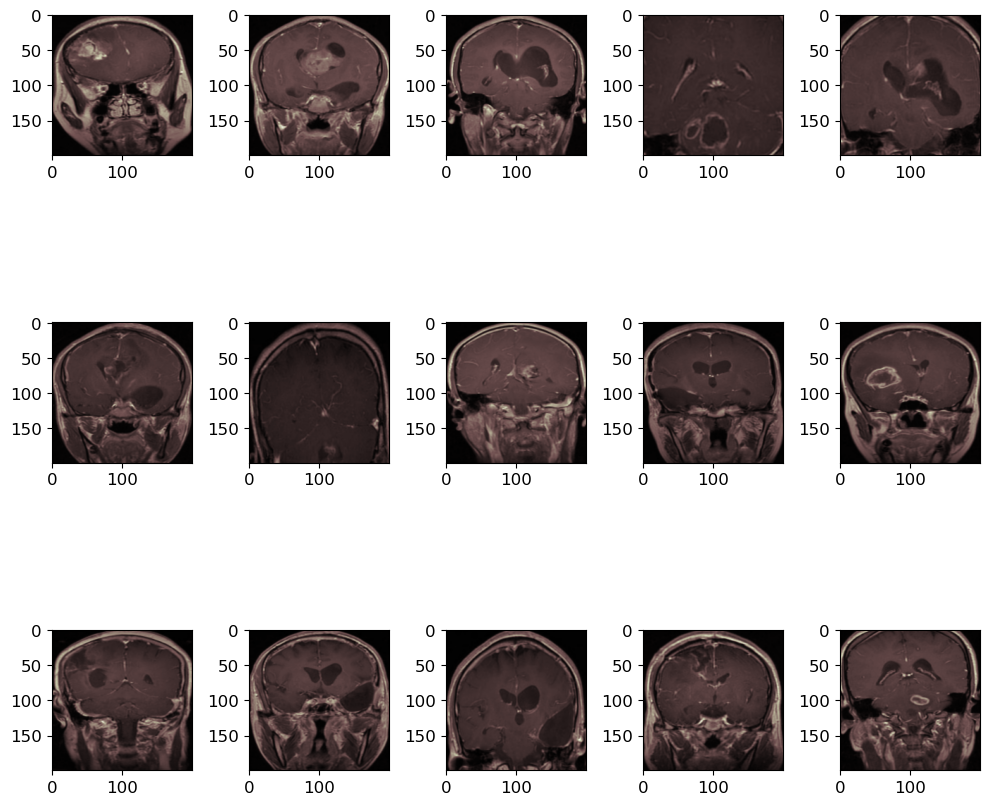

In [23]:
# Checking on the images

images = [x_train[i] for i in range(15)]
fig, axes = plt.subplots(3, 5, figsize = (10, 10))
axes = axes.flatten()
for img, ax in zip(images, axes):
    ax.imshow(img)
plt.tight_layout()
plt.show()

(200, 200)
0.8980392


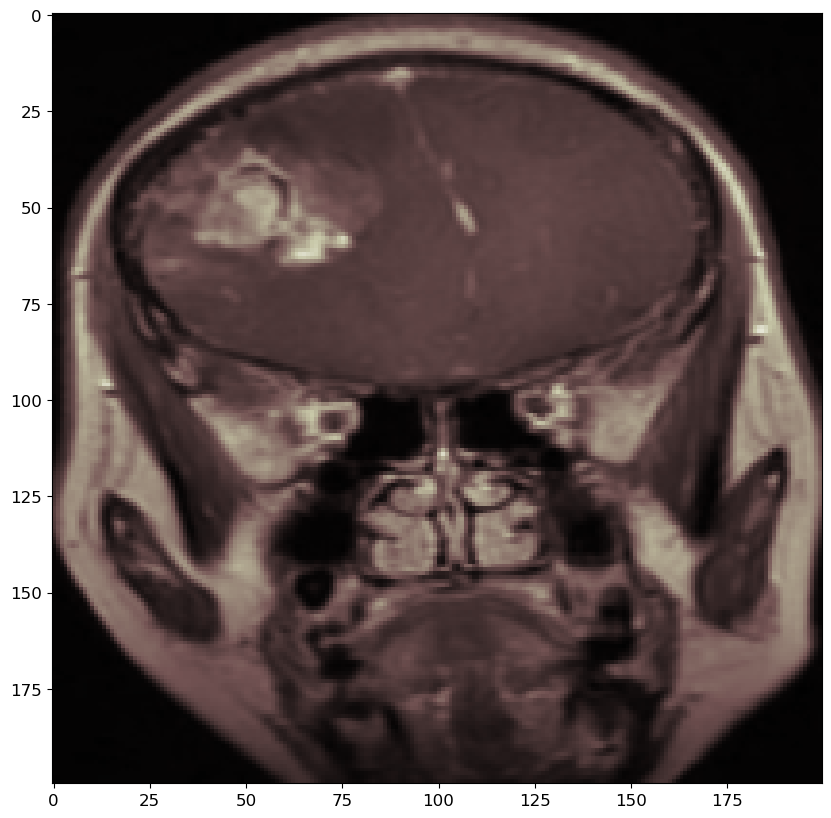

In [24]:
print(x_train[0][:,:,0].shape)
fig, axes = plt.subplots(1, 1, figsize = (10, 10))
axes.imshow(x_train[0])
print(np.max(x_train[0]))
plt.show()

In [25]:
# DCGAN code taken from HOA #8 - will tweak as necessary to serve as a basis for this work.
# The DCGAN seemed to have better initial and overall performance as compared to the standard GAN, so we use it as the baseline here.

In [27]:
def plot_multiple_images(images, n_cols=None):
    n_cols = n_cols or len(images)
    n_rows = (len(images) - 1) // n_cols + 1
    if images.shape[-1] == 1:
        images = np.squeeze(images, axis=-1)
    plt.figure(figsize=(n_cols, n_rows))
    for index, image in enumerate(images):
        plt.subplot(n_rows, n_cols, index + 1)
        plt.imshow(image)#, cmap='bone')
        # plt.imshow(image[:,:,::-1])
        plt.axis("off")

In [28]:
# We try to implement a WGAN, an alternative to the DCGAN which makes use of 
# Wasserstein loss. With this method, the idea is that the generator is trained
# in an alternative way to better approximate the distribution of data in the
# real training set.
# Instead of yielding a binary output, the critic, which "replaces" the discriminator,
# scores the "realness" or "fakeness" of an image, giving a continuous quantity
# that can then be minimized and provide a linear gradient.
# Basically, the WGAN looks for convergence instead of looking for an equilibrium
# point between the generator and discriminator.
# 
# We tweak the code for the original DCGAN, with notes where necessary. 


# The Critic model is the "replacement" for the discriminator. It has several
# differences from the standard discriminator:
# 1) Linear activation instead of sigmoid output layer
# 2) Use -1 for real images and 1 for fake images (THIS IS A CHANGE TO THE TRAINING LOOP)
# 3) Use Wasserstein loss to train the critic and generator models
# 4) Constrain critic model wights to a limited ranged after each mini batch
#    update (for example, between -0.01 and 0.01)
# 5) Update the critic model multiple times for each update of the generator (THIS IS A CHANGE TO THE TRAINING LOOP)
# 6) Use RMSProp with small learning rate and no momentum (THIS IS A CHANGE TO THE COMPILE STEP)
#
# These changes aren't listed in the order they're implemented in the code, so they're labeled appropriately
# in comments wherever they occur.

tf.random.set_seed(42)
np.random.seed(42)

# codings_size = 16
codings_size = 32

init = keras.initializers.RandomNormal(stddev = 0.01)
# , kernel_initializer = init

generator = keras.models.Sequential([
    # keras.layers.Dense(50 * 50 * 128, input_shape=[codings_size]),
    DenseEQ(units=50 * 50 * 128, input_shape=[codings_size]), # equalized LR dense layer
    
    # # Try starting from a smaller size, 25 * 25?
    # DenseEQ(units=25 * 25 * 256, input_shape=[codings_size]),
    keras.layers.Reshape([50, 50, 128]),
    # keras.layers.Reshape([25, 25, 256]),
    keras.layers.BatchNormalization(),
    
    # This will take us from 25 * 25 * 256 -> 50 * 50 * 128 
    # keras.layers.Conv2DTranspose(128, kernel_size=5, strides=2, padding="SAME",
                                 # activation="relu"),
    keras.layers.BatchNormalization(),
    
    keras.layers.Conv2DTranspose(64, kernel_size=5, strides=2, padding="SAME",
                                 activation="relu", kernel_initializer = init),
    keras.layers.BatchNormalization(),
    keras.layers.Conv2DTranspose(3, kernel_size=5, strides=2, padding="SAME",
                                 activation="tanh", kernel_initializer = init),
    # keras.layers.Conv2DTranspose(3, kernel_size=5, strides=2, padding="SAME",
    #                            activation="sigmoid"),
])



# WGAN Change #4
# Weight clipping
# For clip the weights when updating the critic model.
# Earlier in the file, we defined a new class of constraint to be used with the
# kernel_constraint argument of a given layer.
# So in each layer, we include this new clipping.

clip_val = ClipConstraint(0.01)

critic = keras.models.Sequential([
    keras.layers.Conv2D(64, kernel_size=5, strides=2, padding="SAME",
                        activation=keras.layers.LeakyReLU(0.2),
                        input_shape=[200, 200, 3], kernel_initializer = init, kernel_constraint=clip_val),
    # keras.layers.Dropout(0.4),
    keras.layers.BatchNormalization(),
    keras.layers.Conv2D(128, kernel_size=5, strides=2, padding="SAME",
                        activation=keras.layers.LeakyReLU(0.2), kernel_initializer = init, kernel_constraint=clip_val),
    # keras.layers.Dropout(0.4),
    keras.layers.BatchNormalization(),

    # Adding the layer to bring it down from 50 * 50 * 128 -> 25 * 25 * 256
    # keras.layers.Conv2D(256, kernel_size=5, strides=2, padding="SAME",
                        # activation=keras.layers.LeakyReLU(0.2), kernel_initializer = init, kernel_constraint=clip_val),

    # Minibatch std dev layer
    MinibatchStdDevLayer(4),

    keras.layers.Flatten(),

    # WGAN Change #1
    # Linear activation output layer
    DenseEQ(units=1, activation="linear")
])


# discriminator = keras.models.Sequential([
#     keras.layers.Conv2D(64, kernel_size=5, strides=2, padding="SAME",
#                         activation=keras.layers.LeakyReLU(0.2),
#                         input_shape=[200, 200, 3]),
#     # keras.layers.Dropout(0.4),
#     keras.layers.BatchNormalization(),
#     keras.layers.Conv2D(128, kernel_size=5, strides=2, padding="SAME",
#                         activation=keras.layers.LeakyReLU(0.2)),
#     # keras.layers.Dropout(0.4),
#     keras.layers.BatchNormalization(),

#     # Adding the layer to bring it down from 50 * 50 * 128 -> 25 * 25 * 256
#     keras.layers.Conv2D(256, kernel_size=5, strides=2, padding="SAME",
#                         activation=keras.layers.LeakyReLU(0.2)),

#     # Minibatch std dev layer
#     # I don't know how to implement custom layers into a sequential model yet. Why does this need an argument, while BatchNormalization doesn't?
#     # keras.layers.Lambda(minibatch_std_layer)(),
#     MinibatchStdDevLayer(4),

#     # maybe keep some dropout layers in addition to batchnormalization?
#     # maybe dropping some neurons will make the model more robust? Or would it 
#     # just work to keep weird unwanted features present/tracked in the remaining
#     # neurons?  

#     keras.layers.Flatten(),
#     # keras.layers.Dense(1, activation="sigmoid")
#     DenseEQ(units=1, activation="sigmoid")
# ])

gan = keras.models.Sequential([generator, critic])

In [29]:
generator.summary()
critic.summary()
gan.summary()

Model: "sequential"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
dense_eq (DenseEQ)           (None, 320000)            10560000  
_________________________________________________________________
reshape (Reshape)            (None, 50, 50, 128)       0         
_________________________________________________________________
batch_normalization (BatchNo (None, 50, 50, 128)       512       
_________________________________________________________________
batch_normalization_1 (Batch (None, 50, 50, 128)       512       
_________________________________________________________________
conv2d_transpose (Conv2DTran (None, 100, 100, 64)      204864    
_________________________________________________________________
batch_normalization_2 (Batch (None, 100, 100, 64)      256       
_________________________________________________________________
conv2d_transpose_1 (Conv2DTr (None, 200, 200, 3)       4

In [31]:
# Since the discriminator is a binary classifier (real/fake image), we can set the loss to binary_crossentropy.
# Similarly, since the GAN as a whole is a binary classifier, we can do the same.
# 
# Once the GAN is created, we must appropriately compile/determine which parts of the model are trainable or not.
# Since "trainable" is only taken into account while compiling, we first compile the discriminator assuming it will be trained. Then, we switch it so that it cannot be trained once the complete GAN is compiled.  
# This way, when we train the GAN, we can separate the training of the discriminator and the generator during each pass - the discriminator is first trained on a combo of real/fake data, then the discriminator is switched to non-trainable, and the
# generator is trained to try and outsmart the discriminator.

In [32]:
# WGAN Change #3
# Implement/use Wasserstein Loss
# The Wasserstein loss can be very simply implemented. It essentially 
# Calculates the average score for real or fake images as such:
def wasserstein_loss(y_true, y_pred):
  # perform element-wise multiplication between the expected labels
  # and the predicted score, then take the mean
  # 
  # This is simpler than the actual implementation of Wasserstein loss
  # from the original paper, but it should work just as well.
  return keras.backend.mean(y_true * y_pred)

In [33]:
# This is putting together the generator and discriminator for the DCGAN
# which used the sequential API.

# WGAN Change #6
# Here, we use the Wasserstein Loss, defined above, alongside RMSProp
opt = keras.optimizers.RMSprop(learning_rate=0.0005)

critic.compile(loss=wasserstein_loss, optimizer=opt)
critic.trainable = False
gan.compile(loss=wasserstein_loss, optimizer=opt)

In [34]:
# In order to train a GAN, we must use a custom training loop similar to the one defined in the HOA/textbook.
# To do this, the training is split into two phases for each training pass/epoch.
# In phase 1, the discriminator is trained on a a combined dataset of real images and images built by the generator using Gaussian noise as input.
# In phase 2, the generator is trained by feeding Gaussian noise to the GAN itself. Now, the images from the generator are tested using the newly-trained discriminator from phase 1. 

In [35]:
# Reshape and rescale the data to account for the tanh activation function in 
# the generator.
# If we use sigmoid instead, we don't need to rescale/readjust later and can 
# comment this part out.
# I think we need to undo this rescaling when plotting/displaying the generated 
# images, since some will have negative values that get clipped when plotted by imshow().

# This should be fine to use for both the DCGAN and the StyleGAN models.


# Turn off for sigmoid activation in generator.
x_train = x_train.reshape(-1, 200, 200, 3) * 2. - 1.

In [36]:
tf.random.set_seed(42)
np.random.seed(42)

batch_size = 32
dataset = tf.data.Dataset.from_tensor_slices(x_train).shuffle(1000)
dataset = dataset.batch(batch_size, drop_remainder=True).prefetch(1)







# Use this to free up the memory taken up by the images.
# Comment this out if you still need the training pictures for something.
del x_train

In [39]:
# create a line plot of loss for the gan and save to file
def plot_history(d1_hist, d2_hist, g_hist):
    # plot history
    plt.plot(d1_hist, label='crit_real')
    plt.plot(d2_hist, label='crit_fake')
    plt.plot(g_hist, label='gen')
    plt.legend()
    plt.savefig('plot_line_plot_loss_WGAN.png')
    plt.close()

# plot_history(c1_hist, c2_hist, g_hist)

In [40]:
def train_wgan(gan, dataset, batch_size, codings_size, n_critic, n_epochs=50):
    generator, critic = gan.layers
    # exp_replay = []

    # Just to keep track of which iteration/loop we're on
    num_iter = 0
    

    c1_hist, c2_hist, g_hist = list(), list(), list()

    for epoch in range(n_epochs):
        print("Epoch {}/{}".format(epoch + 1, n_epochs))
        for X_batch in dataset:
            
            c1_tmp, c2_tmp = list(), list()

            # PHASE 1 - TRAINING THE CRITIC
            # Recall, the critic must be trained multiple times per training 
            # run of the generator. 
            # Here, we use the hyperparameter n_critic to determine how many times
            # this is done.

            for i in range(n_critic):
                # Generating fake images for training the discriminator
                noise = tf.random.normal(shape=[batch_size, codings_size])
                generated_images = generator(noise)
              
                # WGAN Change #2
                # Create combined dataset of both real and newly generated fake images
                # For the WGAN, we set -1 as the real image label and +1 as the fake
                # image label.
                # 
                # Note - here we may want to separate into real/fake half-batches
                # for trainint the critic, so we can get explicit info about
                # critic scores for real/fake images independently (for graphing purposes, maybe?)
                # 
                # X_fake_and_real = tf.concat([generated_images, X_batch], axis=0)
                # X_fake = generated_images
                # X_real = X_batch
                y1_fake = tf.constant([[1.]] * batch_size)
                y1_real = tf.constant([[-1.]] * batch_size)

                # Actually training the critic on the above data.
                critic.trainable = True
                c1_loss = critic.train_on_batch(X_batch, y1_real)
                c1_tmp.append(c1_loss)
                c2_loss = critic.train_on_batch(generated_images, y1_fake)
                c2_tmp.append(c2_loss)
            
            c1_hist.append(np.mean(c1_tmp))
            c2_hist.append(np.mean(c2_tmp))
            # PHASE 2 - TRAINING THE GENERATOR
            
            # Generating noise to feed into the GAN
            noise = tf.random.normal(shape=[batch_size, codings_size])
            y2 = tf.constant([[-1.]] * batch_size)
            
            # Actually training the generator by having the newly-trained critic classify its attempts as real/fake images. 
            critic.trainable = False
            g_loss = gan.train_on_batch(noise, y2)
            g_hist.append(g_loss)         
            
            print('>%d, c1=%.3f, c2=%.3f g=%.3f' % (num_iter+1, c1_hist[-1], c2_hist[-1], g_loss))
            num_iter += 1
            # ######################################################################################
            # # Experience Replay. Not sure if this is working properly.
            # r_index = np.random.randint(batch_size)
            # # exp_replay.append([generated_images[r_index], labels[r_index], gene_labels[r_index]])
            # exp_replay = np.append(exp_replay, generated_images[r_index])
            
            # if len(exp_replay) == batch_size:
            #     # gen_img = np.array([p[0] for p in exp_replay])
            #     # labels = np.array([p[1] for p in exp_replay])
            #     # gen_labels = np.array([p[2] for p in exp_replay])
            #     replay_X_fake_and_real = tf.concat([exp_replay, X_batch], axis=0)
            #     y_replay = tf.constant([[0.]] * batch_size + [[1.]] * batch_size)
                
            #     # Train discriminator or combination of real images and newer/older generated images.
            #     discriminator.trainable = True
            #     exprep_loss_gen = discriminator.train_on_batch(replay_X_fake_and_real, y_replay)
            #     discriminator.trainable = False
                
            #     # Remove older generated images from the buffer list.
            #     exp_replay = np.delete(exp_replay, [0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15])
                
            # ######################################################################################
        
        # Turn off for sigmoid activation in generator.
        # Undo the reshaping/scaling we neede for the tanh activation in the generator.
        fixed_img = (generated_images + 1.)/2.
        plot_multiple_images(fixed_img, 8)
        # plot_multiple_images(generated_images, 8)        
        plt.show()
    plot_history(c1_hist, c2_hist, g_hist)

In [ ]:
# Train the DCGAN.

# tf.random.set_seed(42)
# np.random.seed(42)

train_wgan(gan, dataset, batch_size, codings_size, n_critic=5, n_epochs=64)

In [ ]:
# SAVE_PATH = ''
# gan.save(SAVE_PATH)

In [ ]:
# Notes:
#
# Are the images diverse enough? Maybe try to apply some more corrections to the model
#     -> Experience Replay (check that this is implemented corectly)
# 1) Minibatch std. dev. layer (somewhat implemented?)
# 2) Equalized learning rate (Supposedly implemented? it does run faster, It seems.)
# 3) Pixelwise normalization layer (not yet implemented as of 4/23/23.)

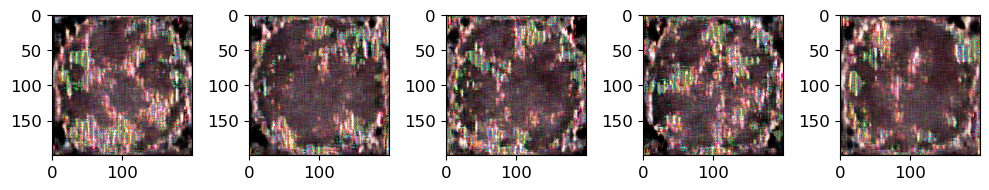

In [43]:
# Print some generated images
noise = tf.random.normal(shape=[5, codings_size])
generated_images = generator(noise)
fixed_img = (generated_images + 1.)/2.

fig, axes = plt.subplots(1, 5, figsize = (10, 10))
axes = axes.flatten()
for img, ax in zip(fixed_img, axes):
    ax.imshow(img)
plt.tight_layout()
plt.show()



# # generated_images = tf.math.l2_normalize(generated_images, axis=())

In [ ]:
# # Print some real images for comparison.
# images = [x_train[i] for i in range(9)]
# fig, axes = plt.subplots(3, 3, figsize = (10, 10))
# axes = axes.flatten()
# for img, ax in zip(images, axes):
#     ax.imshow(img)
#     ax.axis('off')
# plt.tight_layout()
# plt.show()
# # noise = tf.random.normal(shape=[batch_size, codings_size])
# # generated_images = generator(noise)
# # generated_images.shape
# # # generated_images = tf.math.l2_normalize(generated_images, axis=())

In [ ]:
# plot_multiple_images(x_train[1:10], 3)

In [ ]:
# Using the earlier model (or saved model, whichever you choose to load as the generator), generate some images.
# To keep from running into OOM error, split into separate laps that generated 100 images each lap.
#
# Since the original model is trained on around 5712 training images and 1311 test images, we'll generate 7000
# fake images to be split into train/test for the GAN evaluation phase (GQI): 6000 for training and 1000 for testing.

tf.random.set_seed(42)
np.random.seed(42)

num_img = 100
laps_train = 50
laps_test = 10

# Change these to where your generated images are to be saved. This creates the directories if they don't exist.
GEN_TRAIN_PATH = ""
GEN_TEST_PATH = ""

if not os.path.exists(GEN_TRAIN_PATH):
    os.makedirs(GEN_TRAIN_PATH)
    
if not os.path.exists(GEN_TEST_PATH):
    os.makedirs(GEN_TEST_PATH)

    
    
# Used to make the correct label for the saved image files.
file_num_train=0
file_num_test=0
    
for lap in range(laps_train):
    print("Generating training images %s to %s" % (num_img*lap, num_img*(lap + 1)-1) )    
    
    noise = tf.random.normal(shape=[num_img, codings_size])
    generated_images = generator(noise)
    fixed_img = (generated_images + 1.)/2.

    for num in range(num_img):
        tf.keras.preprocessing.image.save_img(GEN_TRAIN_PATH + '\\gen_img_%s.png' % str(file_num_train), generated_images[num])
        file_num_train += 1
        
        
for lap in range(laps_test):
    print("Generating test images %s to %s" % (num_img*lap, num_img*(lap + 1)-1) )    
    
    noise = tf.random.normal(shape=[num_img, codings_size])
    generated_images = generator(noise)
    fixed_img = (generated_images + 1.)/2.

    for num in range(num_img):
        tf.keras.preprocessing.image.save_img(GEN_TEST_PATH + '\\gen_img_%s.png' % str(file_num_test), generated_images[num])
        file_num_test += 1